In [1]:
import pandas as pd

In [7]:
data = pd.read_csv('/content/sample_data/income.csv')
data.head()

,Name,Age,Income($
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Name      22 non-null     object
 1   Age       22 non-null     int64 
 2   Income($  22 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 660.0+ bytes


In [10]:
data.rename(columns = {'Income($':'Income'}, inplace = True)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Name    22 non-null     object
 1   Age     22 non-null     int64 
 2   Income  22 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 660.0+ bytes


In [11]:
import matplotlib.pyplot as plt

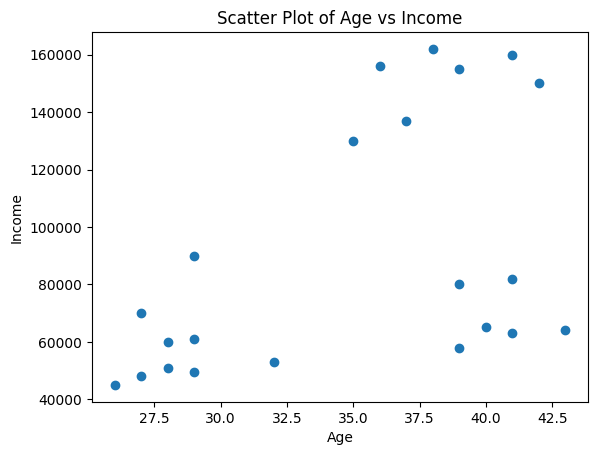

In [12]:
plt.scatter(data['Age'], data['Income'])
plt.xlabel('Age')
plt.ylabel('Income')
plt.title('Scatter Plot of Age vs Income')
plt.show()

# Scaling our data using Min Max Scaler

In [15]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(data[['Age','Income']])
data[['Age','Income']]= scaler.transform(data[['Age','Income']])
data.head()

,Name,Age,Income
0,Rob,0.058824,0.213675
1,Michael,0.176471,0.384615
2,Mohan,0.176471,0.136752
3,Ismail,0.117647,0.128205
4,Kory,0.941176,0.897436


# Clustering

In [16]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters = 3)
y_pred = kmeans.fit_predict(data[['Age','Income']])
y_pred

array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2],
      dtype=int32)

In [17]:
data['Clusters'] = y_pred
data.head()

,Name,Age,Income,Clusters
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,0


In [18]:
#cluster0 data
data[data['Clusters']==0]

,Name,Age,Income,Clusters
4,Kory,0.941176,0.897436,0
5,Gautam,0.764706,0.940171,0
6,David,0.882353,0.982906,0
7,Andrea,0.705882,1.000000,0
8,Brad,0.588235,0.948718,0
9,Angelina,0.529412,0.726496,0
10,Donald,0.647059,0.786325,0


In [19]:
data[data['Clusters']==1]

,Name,Age,Income,Clusters
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
11,Tom,0.000000,0.000000,1
12,Arnold,0.058824,0.025641,1
13,Jared,0.117647,0.051282,1
14,Stark,0.176471,0.038462,1
15,Ranbir,0.352941,0.068376,1


In [20]:
data[data['Clusters']==2]

,Name,Age,Income,Clusters
16,Dipika,0.823529,0.170940,2
17,Priyanka,0.882353,0.153846,2
18,Nick,1.000000,0.162393,2
19,Alia,0.764706,0.299145,2
20,Sid,0.882353,0.316239,2
21,Abdul,0.764706,0.111111,2


# Plotting our Scatterplot to see the distribution of our points

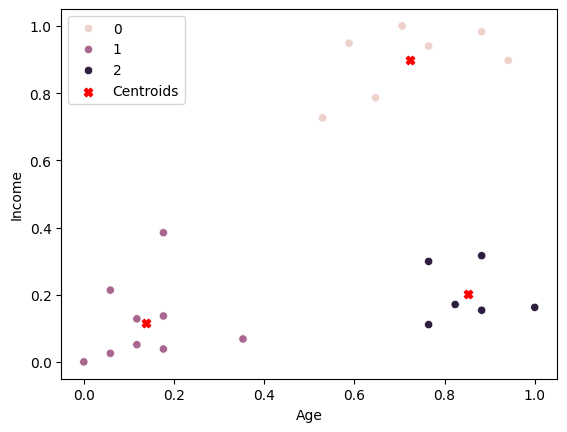

In [23]:
import seaborn as sns
sns.scatterplot(data = data, x = 'Age', y = 'Income',hue = 'Clusters')
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], color = 'red', marker = 'X', label = 'Centroids')
plt.legend()
plt.show()

# We may wish to see the positions of our centroids to see how the distance metrics have been used to identify different clusters

In [22]:
kmeans.cluster_centers_

array([[0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ]])

# Performing the Elbow method to identify the number of optimal clusters

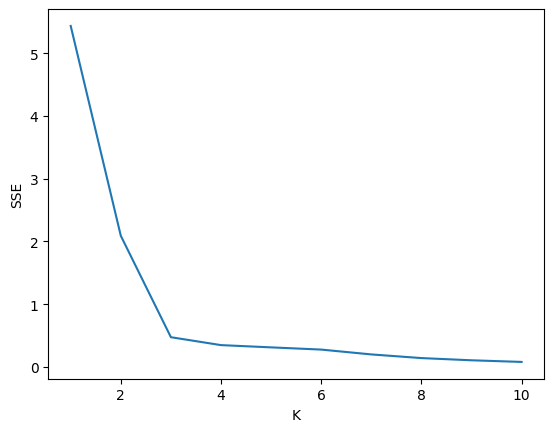

In [25]:
sse = []
kmeans_range = range(1,11)
for k in kmeans_range:
  kmeans = KMeans(n_clusters = k)
  kmeans.fit_predict(data[['Age','Income']])
  sse.append(kmeans.inertia_)

plt.plot(kmeans_range,sse)
plt.xlabel('K')
plt.ylabel('SSE')
plt.show()

The number of the optimal clusters is 3 from the graph

# Silohuet Method

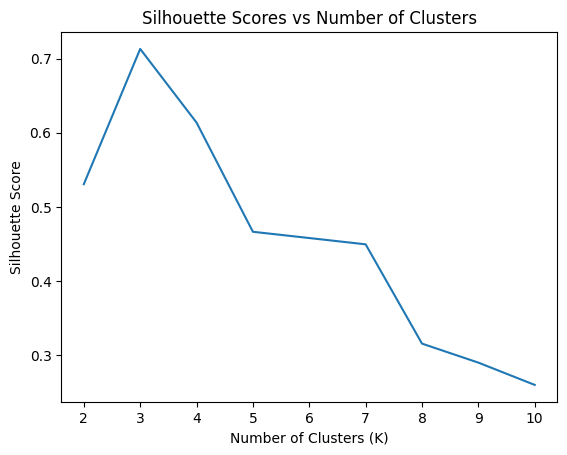

In [26]:
from sklearn.metrics import silhouette_score

silhouette_scores = []
for k in range(2, 11):  # Silhouette score is not defined for k=1
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(data[['Age', 'Income']])
    score = silhouette_score(data[['Age', 'Income']], kmeans.labels_)
    silhouette_scores.append(score)

plt.plot(range(2, 11), silhouette_scores)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores vs Number of Clusters')
plt.show()